<a href="https://colab.research.google.com/github/ThePotatoSensei/Neuron-Simulation/blob/main/HodgkinHuxley.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Load packages for numeric computations (numpy) and plotting (matplotlib)

import numpy as np
import matplotlib.pyplot as plt

# The main functions for the Hodgkin-Huxley model are following this Github repository: https://github.com/swharden/pyHH

# The Hodgkin and Huxley model

In [ ]:
# define the HH model

class HHModel:
    """The HHModel tracks conductances of 3 channels to calculate Vm"""

    # define the behavior of the gating variables behavior
    class Gate:
        """The Gate object manages a channel's kinetics and open state"""
        alpha, beta, state = 0, 0, 0

        def update(self, deltaTms):
            alphaState = self.alpha * (1-self.state)
            betaState = self.beta * self.state
            self.state += deltaTms * (alphaState - betaState)

        def setInfiniteState(self):
            self.state = self.alpha / (self.alpha + self.beta)

    # define default equilibrium potentials and conductances;
    # note that these values may be overwritten when running the program
    ENa, EK, EL = 50, -77, -54.4
    gNa, gK, gL = 120, 36, 0.3
    Cm = 1
    Vrest = -65  # the HH rate equations below are written relative to rest

    def __init__(self, startingVoltage=-65):
        self.m, self.n, self.h = self.Gate(), self.Gate(), self.Gate()
        self.Vm = startingVoltage
        self._UpdateGateTimeConstants(startingVoltage)
        self.m.setInfiniteState()
        self.n.setInfiniteState()
        self.h.setInfiniteState()

    @staticmethod
    def _vtrap(x, y):
        """x / (exp(x/y) - 1), using its limit y at x = 0 to avoid 0/0"""
        return y if abs(x) < 1e-6 else x / np.expm1(x / y)

    # update the voltage-dependent rate constants alpha and beta (1/ms) of each gate
    def _UpdateGateTimeConstants(self, Vm):
        """Update rate constants of all gates based on the given Vm"""
        V = Vm - self.Vrest
        self.n.alpha = .01 * self._vtrap(10-V, 10)
        self.n.beta = .125*np.exp(-V/80)
        self.m.alpha = .1 * self._vtrap(25-V, 10)
        self.m.beta = 4*np.exp(-V/18)
        self.h.alpha = .07*np.exp(-V/20)
        self.h.beta = 1/(np.exp((30-V)/10)+1)

    # update the membrane potential based on conductance-based and other currents
    def _UpdateCellVoltage(self, stimulusCurrent, deltaTms):
        """calculate channel currents using the latest gate time constants"""
        self.INa = np.power(self.m.state, 3) * self.gNa * \
            self.h.state*(self.Vm-self.ENa)
        self.IK = np.power(self.n.state, 4) * self.gK * (self.Vm-self.EK)
        self.IL = self.gL * (self.Vm-self.EL)
        Isum = stimulusCurrent - self.INa - self.IK - self.IL
        self.Vm += deltaTms * Isum / self.Cm

    def _UpdateGateStates(self, deltaTms):
        """calculate new channel open states using latest Vm"""
        self.n.update(deltaTms)
        self.m.update(deltaTms)
        self.h.update(deltaTms)

    def iterate(self, stimulusCurrent, deltaTms):
        self._UpdateGateTimeConstants(self.Vm)
        self._UpdateCellVoltage(stimulusCurrent, deltaTms)
        self._UpdateGateStates(deltaTms)

In [ ]:
# define the simulation to be used

class Simulation:

    # initiate Hodgkin-Huxley model (defined above)
    def __init__(self, model):
        self.model = model
        self.CreateArrays(0, 0)
        pass

    # create arrays to contain variables and measurements
    def CreateArrays(self, pointCount, deltaTms):
        self.times = np.arange(pointCount) * deltaTms
        self.Vm = np.empty(pointCount)
        self.INa = np.empty(pointCount)
        self.IK = np.empty(pointCount)
        self.IL = np.empty(pointCount)
        self.StateN = np.empty(pointCount)
        self.StateM = np.empty(pointCount)
        self.StateH = np.empty(pointCount)

    # run the simulation based on the model,
    # using stimulus waveform and time step size as inputs
    def Run(self, stimulusWaveform, stepSizeMs):
        self.CreateArrays(len(stimulusWaveform), stepSizeMs)
        print(f"simulating {len(stimulusWaveform)} time points...")
        for i in range(len(stimulusWaveform)):
            self.model.iterate(stimulusWaveform[i], stepSizeMs)
            self.Vm[i] = self.model.Vm
            self.INa[i] = self.model.INa
            self.IK[i] = self.model.IK
            self.IL[i] = self.model.IL
            self.StateH[i] = self.model.h.state
            self.StateM[i] = self.model.m.state
            self.StateN[i] = self.model.n.state
        print("simulation complete")

In [ ]:
# run the simulation

# customize a neuron model if desired
model = HHModel()
model.gNa = 120  # typically 120
model.gK = 36  # typically 36
model.EK = -77  # typically -77 mV
model.ENa = 50  # typically +50 mV

# time settings (ms)
dt = 0.01
t = np.arange(int(200 / dt)) * dt

# customize a stimulus waveform (µA/cm²), defined in ms so it works for any dt
stim = np.zeros(len(t))
stim[(t >= 70) & (t < 130)] = 2  # 2 is just below threshold (~2.24); try 2.3, 7 or -10

# let the model settle at its own resting potential before recording
for _ in range(int(50 / dt)):
    model.iterate(0, dt)

# simulate the model cell using the custom waveform
sim = Simulation(model)
sim.Run(stimulusWaveform=stim, stepSizeMs=dt)

simulating 20000 time points...
simulation complete


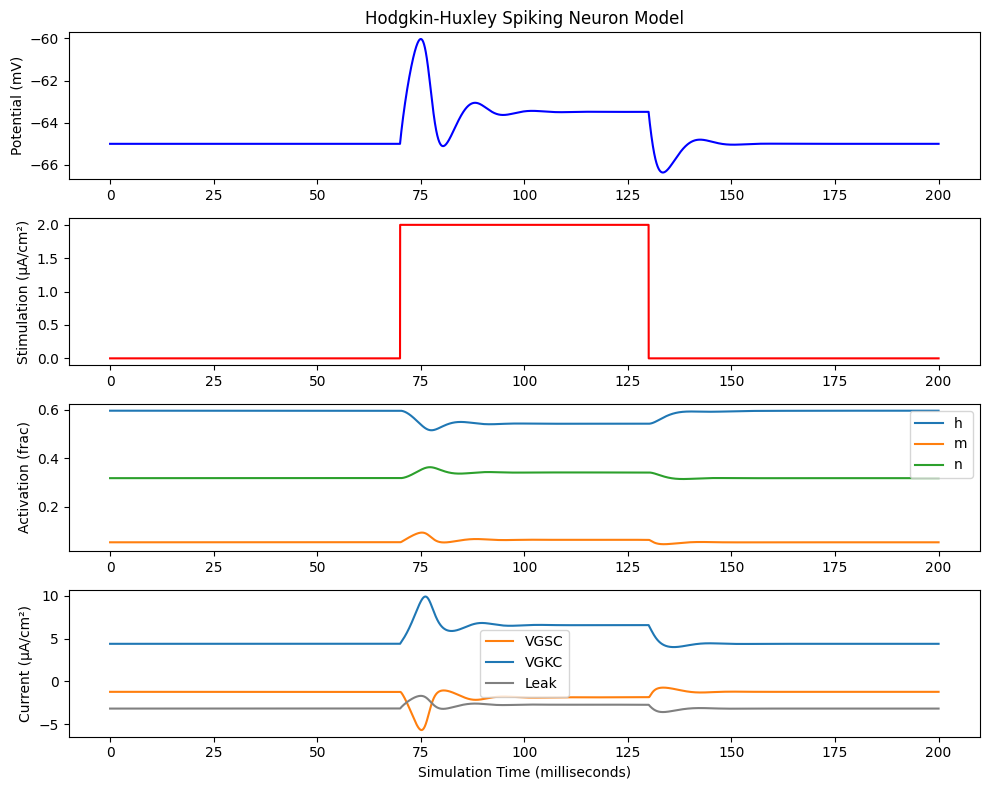

In [ ]:
# plot the results with MatPlotLib
plt.figure(figsize=(10, 8))

ax1 = plt.subplot(411)
ax1.plot(sim.times, sim.Vm, color='b')
ax1.set_ylabel("Potential (mV)")
ax1.set_title("Hodgkin-Huxley Spiking Neuron Model")

ax2 = plt.subplot(412)
ax2.plot(sim.times, stim, color='r')
ax2.set_ylabel("Stimulation (µA/cm²)")

ax3 = plt.subplot(413, sharex=ax1)
ax3.plot(sim.times, sim.StateH, label='h')
ax3.plot(sim.times, sim.StateM, label='m')
ax3.plot(sim.times, sim.StateN, label='n')
ax3.set_ylabel("Activation (frac)")
ax3.legend()

ax4 = plt.subplot(414, sharex=ax1)
ax4.plot(sim.times, sim.INa, label='VGSC', color='tab:orange')
ax4.plot(sim.times, sim.IK, label='VGKC', color='tab:blue')
ax4.plot(sim.times, sim.IL, label='Leak', color='gray')
ax4.set_ylabel("Current (µA/cm²)")
ax4.set_xlabel("Simulation Time (milliseconds)")
ax4.legend()

plt.tight_layout()
plt.show()